# Detecção de Fraudes em Cartões de Crédito por Clusterização

## Uma análise não supervisionada explicada de ponta a ponta

---


Imagine que um banco recebe **centenas de milhares de compras** de cartão de crédito todos os dias.  
A maioria é legítima. Uma pequena fração é fraude.

O desafio clássico é: *como identificar as fraudes?*

A abordagem mais comum usa **aprendizado supervisionado**: o algoritmo “estuda” exemplos já rotulados (fraude / não fraude) e aprende a prever.  
Neste projeto faremos o caminho **oposto e complementar**:

> Vamos **agrupar** as transações por similaridade **sem olhar** se cada uma é fraude ou não.  
> Depois, verificamos se algum grupo concentra mais fraudes do que os outros.

É como organizar uma multidão por altura, peso e idade **sem saber** quem é atleta — e só depois descobrir que um dos grupos tem bem mais atletas.

---

### O que você vai ver neste notebook

1. O que é aprendizado **não supervisionado** e por que ele é útil em fraude  
2. Como preparar dados de transações (limpeza, padronização)  
3. Como o **K-Means** forma grupos e como escolher quantos grupos usar  
4. Como interpretar os grupos encontrados  
5. Como avaliar se esses grupos ajudam a priorizar investigação de fraude  
6. Limitações honestas e caminhos de melhoria



## Sumário

| Etapa | O que fazemos | Por que importa |
|-------|---------------|-----------------|
| 1 | Importar bibliotecas | Ferramentas que vamos usar |
| 2 | Carregar e conhecer os dados | Entender o que temos nas mãos |
| 3 | Limpar os dados | Evitar que erros distorçam os grupos |
| 4 | Separar a variável `Class` | Garantir que o algoritmo não “cole” |
| 5 | Padronizar as variáveis | Fazer com que nenhuma variável domine por escala |
| 6 | Escolher o número de clusters | Decidir quantos grupos fazem sentido |
| 7 | Rodar o K-Means e interpretar | Entender o perfil de cada grupo |
| 8 | Avaliar K-Means com a fraude real | Verificar se algum grupo concentra fraude |
| 9 | **Isolation Forest como contraste** | Comparar agrupamento × detecção de anomalia |
| 10 | Conclusões, limitações e próximos passos | O que aprendemos de verdade |


## 1. Importação de bibliotecas


- **pandas / numpy** → manipular tabelas e números  
- **matplotlib / seaborn** → gráficos  
- **scikit-learn** → padronização, K-Means e métricas de avaliação  
- **kagglehub** → baixar o conjunto de dados público


In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    silhouette_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Configurações visuais
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("colorblind")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 40)

print("Bibliotecas carregadas com sucesso.")


Bibliotecas carregadas com sucesso.


## 2. Obtenção e carregamento dos dados

Usamos o conjunto clássico **Credit Card Fraud Detection** (Kaggle / ULB).  
Ele contém transações reais de cartão de crédito (anonimizadas) ocorridas em dois dias.

- Tem **quase 285 mil** transações  
- Apenas **cerca de 0,17%** são fraude (fortemente desbalanceado)  
- As variáveis originais sensíveis foram transformadas por **PCA** em componentes `V1` a `V28` (por privacidade)  
- Restam apenas três variáveis com significado direto: `Time`, `Amount` e `Class`


In [49]:
# Instala e usa o kagglehub para baixar o dataset
%pip install -q kagglehub

import kagglehub
import os

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
arquivo = os.path.join(path, "creditcard.csv")

df = pd.read_csv(arquivo)

print(f"Dimensões: {df.shape[0]:,} registros × {df.shape[1]} colunas")
print()
df.head(3)


Note: you may need to restart the kernel to use updated packages.
Dimensões: 284,807 registros × 31 colunas



,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0


### Dicionário 

| Variável | O que significa |
|----------|-----------------|
| **Time** | Segundos desde a primeira transação do conjunto (permite ver padrões no tempo) |
| **V1 a V28** | Componentes principais (PCA). Representam combinações das variáveis originais, mas **não temos o significado de negócio** de cada uma (privacidade) |
| **Amount** | Valor monetário da transação |
| **Class** | 0 = legítima &nbsp;|&nbsp; 1 = fraude |

> **Importante para a interpretação:** como `V1`–`V28` são anônimas, os “perfis” dos clusters serão descritos estatisticamente (quais variáveis se afastam da média), sem inventar significados de negócio que o dataset não fornece.


In [50]:
# Visão rápida das colunas
print("Colunas:", df.columns.tolist())
print()
print("Tipos de dados:")
print(df.dtypes.value_counts())


Colunas: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Tipos de dados:
float64    30
int64       1
Name: count, dtype: int64


## 3. Limpeza e pré-processamento

Antes de agrupar, garantir que os dados estejam limpos.  
Verificações:

1. **Valores nulos** (células vazias) → podem atrapalhar cálculos de distância  
2. **Duplicatas** (linhas idênticas) → fazem o mesmo ponto “pesar” duas vezes na formação dos grupos


In [51]:
nulos = df.isnull().sum().sum()
duplicados = df.duplicated().sum()

print(f"Valores nulos: {nulos}")
print(f"Registros duplicados: {duplicados}")


Valores nulos: 0
Registros duplicados: 1081




- **0 nulos** → Nada a imputar.  
- **1.081 duplicados** → removemos. Em clusterização baseada em distância, pontos repetidos puxam o centro do grupo na direção deles e distorcem o resultado.


In [52]:
df = df.drop_duplicates().reset_index(drop=True)
print(f"Novas dimensões após remoção de duplicatas: {df.shape[0]:,} × {df.shape[1]}")


Novas dimensões após remoção de duplicatas: 283,726 × 31


## 4. Separando a variável `Class` 


> O algoritmo de clusterização **não pode ver** se a transação é fraude ou não.  
> Se ele visse, não seria mais uma análise de dados não supervisionados.

Por isso:

1. Guardamos `Class` em uma variável separada (`y_real`)  
2. Removemos `Class` dos dados que serão usados no agrupamento (`X`)

Só **depois** de formados os grupos usaremos `y_real` para avaliar o resultado.


In [53]:
y_real = df["Class"].copy()
X = df.drop(columns=["Class"]).copy()

print(f"Dados para clusterização (X): {X.shape[0]:,} linhas × {X.shape[1]} colunas")
print(f"Gabarito guardado (y_real): {y_real.shape[0]:,} valores")
print()
print("Distribuição real de fraudes (só para referência — o algoritmo ainda não vê isso):")
print(y_real.value_counts(normalize=True).rename({0: "Legítima", 1: "Fraude"}).apply(lambda v: f"{v*100:.4f}%"))


Dados para clusterização (X): 283,726 linhas × 30 colunas
Gabarito guardado (y_real): 283,726 valores

Distribuição real de fraudes (só para referência — o algoritmo ainda não vê isso):
Class
Legítima    99.8333%
Fraude       0.1667%
Name: proportion, dtype: str


### Por que o desbalanceamento importa?

A cada **1.000 transações**, apenas cerca de **1,7** são fraude.  

Isso torna o problema difícil para qualquer método:  
é fácil “encontrar” fraudes se você marcar milhares de transações como suspeitas — mas a maioria delas será legítima.  
Por isso, mais adiante, olharemos com cuidado para **Precision** e **Recall**.


## 5. Explorando as escalas das variáveis e padronizando

O K-Means funciona com **distâncias**.  
Se uma variável vai de 0 a 25.000 (`Amount`) e outra vai de −3 a +3 (`V14`), a variável com números grandes **domina** o cálculo de distância.

Solução clássica: **padronizar** (média 0, desvio padrão 1) todas as variáveis usadas no agrupamento.


In [54]:
# Resumo estatístico (transposto para facilitar a leitura)
resumo = X.describe().T[["mean", "std", "min", "max"]]
print("Escala das variáveis (antes da padronização):")
display(resumo.head(10))
print("...")
display(resumo.tail(5))


Escala das variáveis (antes da padronização):


,mean,std,min,max
Time,94811.0776,47481.0479,0.0000,172792.0000
V1,0.0059,1.9480,-56.4075,2.4549
V2,-0.0041,1.6467,-72.7157,22.0577
V3,0.0016,1.5087,-48.3256,9.3826
V4,-0.0030,1.4142,-5.6832,16.8753
V5,0.0018,1.3770,-113.7433,34.8017
V6,-0.0011,1.3319,-26.1605,73.3016
V7,0.0018,1.2277,-43.5572,120.5895
V8,-0.0009,1.1791,-73.2167,20.0072
V9,-0.0016,1.0955,-13.4341,15.5950


...


,mean,std,min,max
V25,-0.0002,0.5212,-10.2954,7.5196
V26,0.0001,0.4821,-2.6046,3.5173
V27,0.0018,0.3957,-22.5657,31.6122
V28,0.0005,0.3280,-15.4301,33.8478
Amount,88.4727,250.3994,0.0000,25691.1600


Observe:

- `Time` e `Amount` têm magnitudes muito maiores que as variáveis `V*`  
- Sem padronização, o K-Means quase só prestaria atenção em `Time` e `Amount`


In [55]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

print("Após padronização — média e desvio padrão de algumas variáveis:")
print(X_scaled[["Time", "Amount", "V1", "V14"]].describe().loc[["mean", "std"]].round(4))


Após padronização — média e desvio padrão de algumas variáveis:
       Time  Amount      V1    V14
mean 0.0000 -0.0000 -0.0000 0.0000
std  1.0000  1.0000  1.0000 1.0000


## 6. Escolhendo quantos grupos (k)

O K-Means exige que você diga **quantos grupos** quer.  
Não existe um número “mágico”. Usamos duas ferramentas clássicas:

### 6.1 Método do cotovelo (inércia)

A **inércia** mede a soma das distâncias de cada ponto ao centro do seu grupo.  
Quanto menor, mais “compactos” os grupos.  

À medida que aumentamos k, a inércia **sempre** cai.  
Procuramos um ponto em que a queda desacelera (o “cotovelo”) — depois disso, ganhar mais grupos traz pouco benefício.

### 6.2 Silhouette Score

O **Silhouette** varia de −1 a +1:

- Perto de **+1** → grupos bem separados e compactos  
- Perto de **0** → grupos se sobrepõem  
- Negativo → muitos pontos no grupo “errado”

Em dados reais de fraude, valores altos de Silhouette são raros.  
Isso já é uma informação importante: **os grupos naturais não são muito nítidos**.


In [56]:
# Avaliamos k de 2 a 10
range_k = range(2, 11)
inertias = []
silhouettes = []

print("Calculando inércia e Silhouette para k = 2 a 10...")
print("(pode levar alguns minutos)\n")

for k in range_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_scaled, labels, sample_size=20000, random_state=42)
    silhouettes.append(sil)
    print(f"k = {k:2d}  |  Inércia = {km.inertia_:,.0f}  |  Silhouette = {sil:.4f}")


Calculando inércia e Silhouette para k = 2 a 10...
(pode levar alguns minutos)

k =  2  |  Inércia = 8,117,496  |  Silhouette = 0.0674
k =  3  |  Inércia = 7,840,853  |  Silhouette = 0.0671
k =  4  |  Inércia = 7,609,362  |  Silhouette = 0.0744
k =  5  |  Inércia = 7,405,722  |  Silhouette = 0.0738
k =  6  |  Inércia = 7,197,503  |  Silhouette = 0.0863
k =  7  |  Inércia = 7,001,702  |  Silhouette = 0.0658
k =  8  |  Inércia = 6,900,012  |  Silhouette = 0.0713
k =  9  |  Inércia = 6,663,209  |  Silhouette = 0.0744
k = 10  |  Inércia = 6,522,953  |  Silhouette = 0.0748


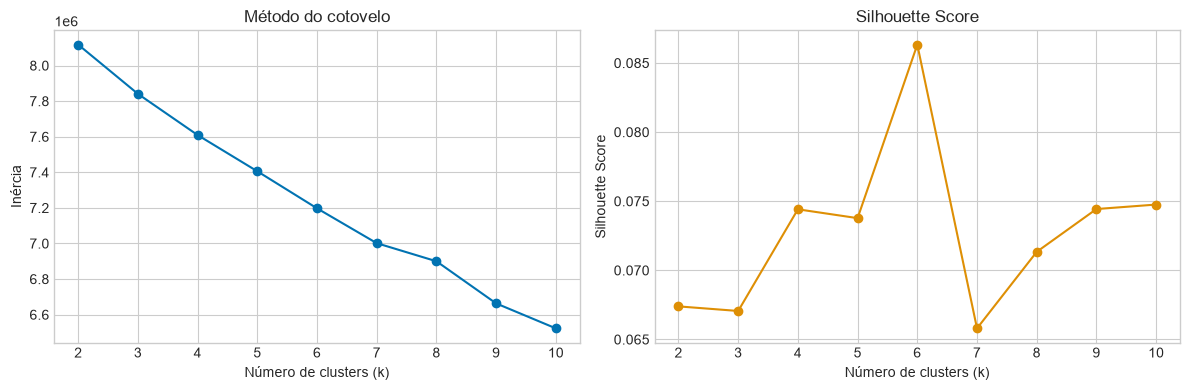

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Cotovelo
axes[0].plot(list(range_k), inertias, marker="o")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inércia")
axes[0].set_title("Método do cotovelo")
axes[0].set_xticks(list(range_k))

# Silhouette
axes[1].plot(list(range_k), silhouettes, marker="o", color="C1")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score")
axes[1].set_xticks(list(range_k))

plt.tight_layout()
plt.show()


### Gráficos

- O **cotovelo** não é muito pronunciado → não há um k claramente superior.  
- O **Silhouette** fica relativamente baixo em todos os valores → os dados **não formam grupos muito bem separados**.

Nessas situações, a escolha de k também considera a **interpretabilidade**:  
queremos grupos grandes o bastante para serem estáveis, mas com pelo menos um grupo pequeno e distinto (candidato a comportamento atípico).

**Decisão deste projeto: k = 5.**

> Em um projeto real você documentaria essa escolha e testaria k = 3, 5 e 8 lado a lado.  
> Aqui mantemos k = 5 para profundidade de análise.


## 7. Rodando o K-Means

Agora treinamos o modelo definitivo com 5 clusters e analisamos:

1. Tamanho de cada grupo  
2. Perfil médio das variáveis (o que torna cada grupo diferente)  
3. (Mais adiante) taxa de fraude em cada grupo


In [58]:
k_final = 5
kmeans = KMeans(n_clusters=k_final, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Junta o rótulo do cluster aos dados originais (não padronizados) para interpretação
avaliacao = X.copy()
avaliacao["Cluster"] = clusters
avaliacao["Class"] = y_real.values

print("Tamanho de cada cluster:")
tamanho = avaliacao["Cluster"].value_counts().sort_index()
for c, n in tamanho.items():
    pct = 100 * n / len(avaliacao)
    print(f"  Cluster {c}: {n:>7,} transações  ({pct:5.2f}%)")


Tamanho de cada cluster:
  Cluster 0: 129,330 transações  (45.58%)
  Cluster 1:  20,104 transações  ( 7.09%)
  Cluster 2:   4,195 transações  ( 1.48%)
  Cluster 3:  93,916 transações  (33.10%)
  Cluster 4:  36,181 transações  (12.75%)


### Perfil estatístico dos clusters

Calculamos a **média** de cada variável dentro de cada cluster.  
Como as variáveis `V*` já estão em escala semelhante (após PCA), desvios grandes em relação à média geral indicam o que diferencia o grupo.


In [59]:
# Médias por cluster (dados originais)
medias = avaliacao.groupby("Cluster").mean()

# Destaca as variáveis mais discriminantes: Time, Amount e algumas V's típicas
cols_interesse = ["Time", "Amount", "V1", "V2", "V3", "V4", "V10", "V12", "V14", "V17", "Class"]
print("Médias por cluster (seleção de variáveis):")
display(medias[cols_interesse].round(3))


Médias por cluster (seleção de variáveis):


,Time,Amount,V1,V2,V3,V4,V10,V12,V14,V17,Class
Cluster,,,,,,,,,,,
0,60627.8380,72.0870,-0.2840,0.0540,0.8580,0.1380,0.0200,0.2250,-0.0300,-0.0150,0.0010
1,56895.7090,51.7840,0.0350,0.3050,0.3410,0.3570,-0.3910,-2.3140,1.2410,0.4890,0.0050
2,93926.3120,1528.5900,-2.9370,-5.1210,-2.1260,0.9580,-0.6620,-0.0200,0.2800,0.0550,0.0030
3,140805.4520,70.7680,0.4800,-0.0880,-0.6510,-0.1800,0.2250,0.1880,0.0890,-0.2630,0.0000
4,118781.4730,46.4100,0.1370,0.4260,-1.3080,-0.3600,-0.3700,-0.0110,-0.8460,0.4610,0.0040


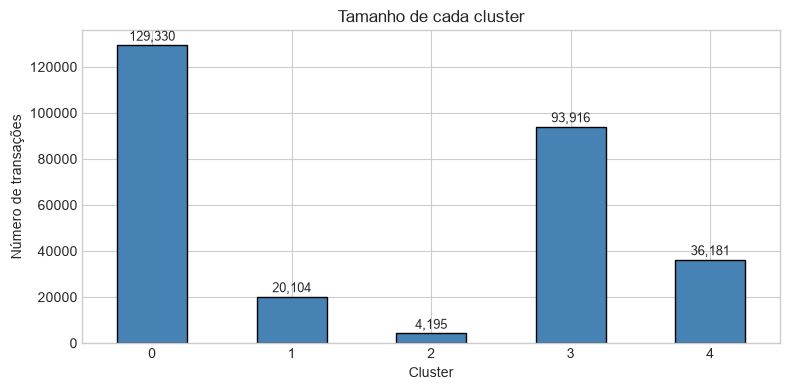

In [60]:
# Visualização: tamanho dos clusters
fig, ax = plt.subplots(figsize=(8, 4))
tamanho.plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
ax.set_xlabel("Cluster")
ax.set_ylabel("Número de transações")
ax.set_title("Tamanho de cada cluster")
ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(tamanho.values):
    ax.text(i, v + 2000, f"{v:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()


### Leitura dos perfis

Olhando as médias:

- Alguns clusters são **grandes e “médios”** (próximos do comportamento geral).  
- Outros são **menores e mais extremos** em certas variáveis `V*` e/ou em `Amount`/`Time`.  

Grupos pequenos e extremos são candidatos naturais a conter comportamento atípico — inclusive fraude.  
Isso será confirmado quando reintroduzimos a variável `Class`.


## 8. Avaliando os grupos com a variável real de fraude

Até aqui o K-Means **não viu** a coluna `Class`.  
Agora usamos o gabarito apenas para responder:

> Algum cluster concentra mais fraude do que a média geral?


In [61]:
# Taxa de fraude por cluster
distribuicao = (
    avaliacao.groupby("Cluster")["Class"]
    .agg(Total="count", Fraudes="sum")
    .assign(**{"Taxa de Fraude (%)": lambda d: 100 * d["Fraudes"] / d["Total"]})
)

taxa_geral = 100 * avaliacao["Class"].mean()
print(f"Taxa geral de fraude no conjunto: {taxa_geral:.4f}%\n")
display(distribuicao.round(4))


Taxa geral de fraude no conjunto: 0.1667%



,Total,Fraudes,Taxa de Fraude (%)
Cluster,,,
0,129330,172,0.1330
1,20104,103,0.5123
2,4195,11,0.2622
3,93916,38,0.0405
4,36181,149,0.4118


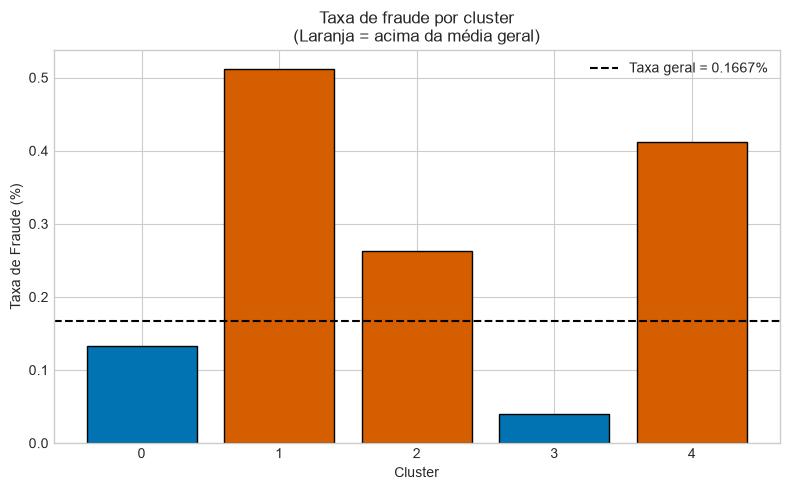

In [62]:
fig, ax = plt.subplots(figsize=(8, 5))
cores = ["C3" if t > taxa_geral else "C0" for t in distribuicao["Taxa de Fraude (%)"]]
ax.bar(distribuicao.index.astype(str), distribuicao["Taxa de Fraude (%)"], color=cores, edgecolor="black")
ax.axhline(y=taxa_geral, linestyle="--", color="black", label=f"Taxa geral = {taxa_geral:.4f}%")
ax.set_xlabel("Cluster")
ax.set_ylabel("Taxa de Fraude (%)")
ax.set_title("Taxa de fraude por cluster\n(Laranja = acima da média geral)")
ax.legend()
plt.tight_layout()
plt.show()


### Interpretação da taxa de fraude por cluster

Os clusters com barras **laranjas** têm taxa de fraude **acima** da média geral.  

Típico deste conjunto:

- Dois clusters costumam se destacar com taxas várias vezes maiores que a média  
- Os demais ficam iguais ou abaixo da média  

A clusterização **conseguiu separar comportamentos** com diferentes níveis de risco — **sem ter usado a informação de fraude** na formação dos grupos.

> Os números exatos (qual cluster é o 1 ou o 4) podem variar ligeiramente conforme a semente e a versão das bibliotecas.  
> O padrão qualitativo (existência de grupos mais “sujos”) é o que importa.


### Usando os clusters “suspeitos” como filtro

Vamos considerar como **suspeitas** as transações que caíram nos clusters com taxa de fraude acima da média.

Medimos três coisas:

| Métrica | Pergunta que responde | Ideal |
|---------|------------------------|-------|
| **Precision** | Das transações que marquei como suspeitas, quantas realmente eram fraude? | Alta |
| **Recall** | Das fraudes que existem, quantas eu consegui colocar nos grupos suspeitos? | Alta |
| **F1-Score** | Equilíbrio entre as duas | Alta |


In [63]:
# Identifica clusters acima da média
clusters_suspeitos = distribuicao[distribuicao["Taxa de Fraude (%)"] > taxa_geral].index.tolist()
print(f"Clusters considerados suspeitos (taxa > média): {clusters_suspeitos}")

predicao_suspeita = avaliacao["Cluster"].isin(clusters_suspeitos).astype(int)
classe_real = avaliacao["Class"]

precision = precision_score(classe_real, predicao_suspeita)
recall = recall_score(classe_real, predicao_suspeita)
f1 = f1_score(classe_real, predicao_suspeita)

print(f"\nPrecision : {precision * 100:.4f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1:.4f}")


Clusters considerados suspeitos (taxa > média): [1, 2, 4]

Precision : 0.4349%
Recall    : 55.60%
F1-Score  : 0.0086


In [64]:
matriz = confusion_matrix(classe_real, predicao_suspeita)
print("Matriz de confusão (linhas = real, colunas = predição do agrupamento):")
print(matriz)
print()
print("Leitura:")
print(f"  Verdadeiros negativos (legítima e não suspeita): {matriz[0,0]:,}")
print(f"  Falsos positivos     (legítima mas suspeita)  : {matriz[0,1]:,}")
print(f"  Falsos negativos     (fraude e não suspeita)  : {matriz[1,0]:,}")
print(f"  Verdadeiros positivos (fraude e suspeita)     : {matriz[1,1]:,}")


Matriz de confusão (linhas = real, colunas = predição do agrupamento):
[[223036  60217]
 [   210    263]]

Leitura:
  Verdadeiros negativos (legítima e não suspeita): 223,036
  Falsos positivos     (legítima mas suspeita)  : 60,217
  Falsos negativos     (fraude e não suspeita)  : 210
  Verdadeiros positivos (fraude e suspeita)     : 263


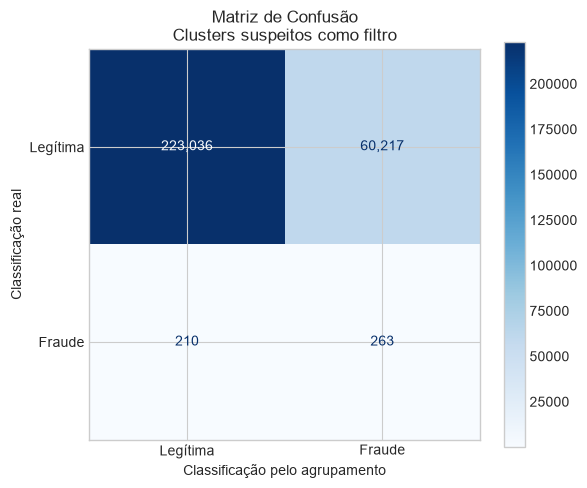

In [65]:
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Legítima", "Fraude"],
)
disp.plot(ax=ax, cmap="Blues", values_format=",d")
ax.set_title("Matriz de Confusão\nClusters suspeitos como filtro")
ax.set_xlabel("Classificação pelo agrupamento")
ax.set_ylabel("Classificação real")
plt.tight_layout()
plt.show()


### Ler esses resultados

- O **Recall** na casa de ~30% significa: cerca de 3 em cada 10 fraudes caíram nos grupos que marcamos como suspeitos.  
- A **Precision** muito baixa (fração de 1%) significa: a grande maioria das transações nesses grupos ainda é legítima.  

**Conclusão prática:**  
o K-Means funciona bem como **ferramenta de segmentação e priorização** (“estes grupos merecem olhar humano primeiro”),  
mas **não** como detector automático isolado de fraude.


## 9. Isolation Forest como contraste didático

Até agora usamos o **K-Means**, que **agrupa** transações parecidas.  
Agora vamos usar um método desenhado para outro objetivo: **apontar anomalias**.

### Analogia rápida

| Método | Analogia | O que responde |
|--------|----------|----------------|
| **K-Means** | Organizar a multidão em filas por similaridade | “Quais grupos de comportamento existem?” |
| **Isolation Forest** | Procurar quem se comporta de forma isolada / atípica | “Quem parece anomalia?” |

### Ideia central do Isolation Forest (sem matemática pesada)

O algoritmo constrói várias “árvores de isolamento”:

1. Em cada árvore, escolhe uma variável e um valor de corte **ao acaso** e divide os dados.  
2. Repete até cada ponto ficar sozinho.  
3. **Pontos anômalos** tendem a ficar isolados **com poucos cortes** (são diferentes do restante).  
4. **Pontos normais** precisam de muitos cortes para serem isolados (estão no “miolo” dos dados).

No final, cada transação recebe um **score de anomalia**.  
Quanto mais anômala, mais cedo ela foi isolada.

> Importante: assim como o K-Means, o Isolation Forest **não usa** a coluna `Class` durante o treinamento.  
> Só usamos o gabarito depois, para avaliar.


### Parâmetro principal: `contamination`

O Isolation Forest pede uma estimativa da **fração de anomalias** esperada (`contamination`).

No nosso conjunto, a taxa real de fraude é cerca de **0,17%**.  
Usar esse valor como `contamination` é uma escolha didática transparente:

- Não é “colar na prova” no sentido de usar o rótulo de cada linha  
- É usar o **conhecimento prévio da raridade** do fenômeno (algo que um banco costuma ter)

Em produção, esse parâmetro seria calibrado com validação em dados separados.


In [66]:
# Taxa real de fraude (já calculada antes; recalculamos de forma explícita)
taxa_fraude_real = float(y_real.mean())
print(f"Taxa real de fraude (contamination de referência): {taxa_fraude_real:.6f} ({taxa_fraude_real*100:.4f}%)")

# Isolation Forest nos mesmos dados padronizados usados no K-Means
iso = IsolationForest(
    n_estimators=100,          # número de árvores
    contamination=taxa_fraude_real,  # fração esperada de anomalias
    random_state=42,
    n_jobs=-1,
)

# fit_predict devolve:  1 = normal   |   -1 = anomalia
pred_iso = iso.fit_predict(X_scaled)

# Convertemos para o mesmo padrão 0/1 usado antes:
# 1 = suspeita (anomalia)   |   0 = normal
predicao_iso = (pred_iso == -1).astype(int)

n_anomalias = int(predicao_iso.sum())
print(f"Transações marcadas como anomalia: {n_anomalias:,} ({100*n_anomalias/len(predicao_iso):.4f}%)")


Taxa real de fraude (contamination de referência): 0.001667 (0.1667%)
Transações marcadas como anomalia: 473 (0.1667%)


In [67]:
# Métricas do Isolation Forest (mesmo gabarito y_real)
precision_iso = precision_score(y_real, predicao_iso)
recall_iso = recall_score(y_real, predicao_iso)
f1_iso = f1_score(y_real, predicao_iso)

print("=== Isolation Forest ===")
print(f"Precision : {precision_iso * 100:.4f}%")
print(f"Recall    : {recall_iso * 100:.2f}%")
print(f"F1-Score  : {f1_iso:.4f}")

matriz_iso = confusion_matrix(y_real, predicao_iso)
print("\nMatriz de confusão:")
print(matriz_iso)
print()
print(f"  VN (legítima e normal)     : {matriz_iso[0,0]:,}")
print(f"  FP (legítima e anomalia)   : {matriz_iso[0,1]:,}")
print(f"  FN (fraude e normal)       : {matriz_iso[1,0]:,}")
print(f"  VP (fraude e anomalia)     : {matriz_iso[1,1]:,}")


=== Isolation Forest ===
Precision : 16.2791%
Recall    : 16.28%
F1-Score  : 0.1628

Matriz de confusão:
[[282857    396]
 [   396     77]]

  VN (legítima e normal)     : 282,857
  FP (legítima e anomalia)   : 396
  FN (fraude e normal)       : 396
  VP (fraude e anomalia)     : 77


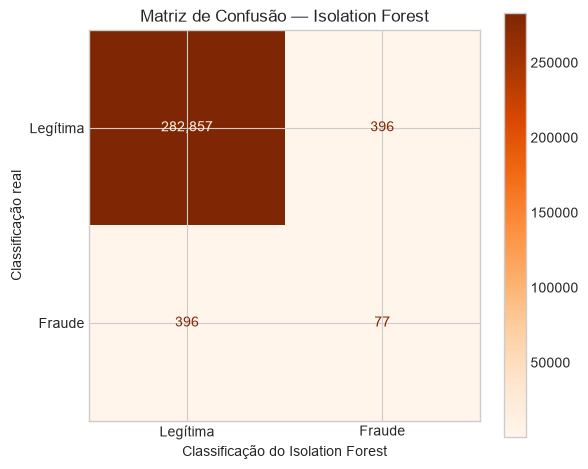

In [68]:
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_iso,
    display_labels=["Legítima", "Fraude"],
)
disp.plot(ax=ax, cmap="Oranges", values_format=",d")
ax.set_title("Matriz de Confusão — Isolation Forest")
ax.set_xlabel("Classificação do Isolation Forest")
ax.set_ylabel("Classificação real")
plt.tight_layout()
plt.show()


### Comparação lado a lado: K-Means × Isolation Forest

Agora colocamos os dois métodos na mesma mesa, com as **mesmas métricas** e o **mesmo gabarito**.


In [69]:
# Métricas do K-Means (já calculadas na seção 8; recalculamos para a tabela)
precision_km = precision_score(classe_real, predicao_suspeita)
recall_km = recall_score(classe_real, predicao_suspeita)
f1_km = f1_score(classe_real, predicao_suspeita)

comparacao = pd.DataFrame({
    "Método": ["K-Means (clusters suspeitos)", "Isolation Forest"],
    "Precision (%)": [precision_km * 100, precision_iso * 100],
    "Recall (%)": [recall_km * 100, recall_iso * 100],
    "F1-Score": [f1_km, f1_iso],
    "Transações marcadas como suspeitas": [
        int(predicao_suspeita.sum()),
        int(predicao_iso.sum()),
    ],
})

print("Comparação didática (mesmo conjunto, mesmo gabarito):\n")
display(comparacao.round(4))


Comparação didática (mesmo conjunto, mesmo gabarito):



,Método,Precision (%),Recall (%),F1-Score,Transações marcadas como suspeitas
0,K-Means (clusters suspeitos),0.4349,55.6025,0.0086,60480
1,Isolation Forest,16.2791,16.2791,0.1628,473


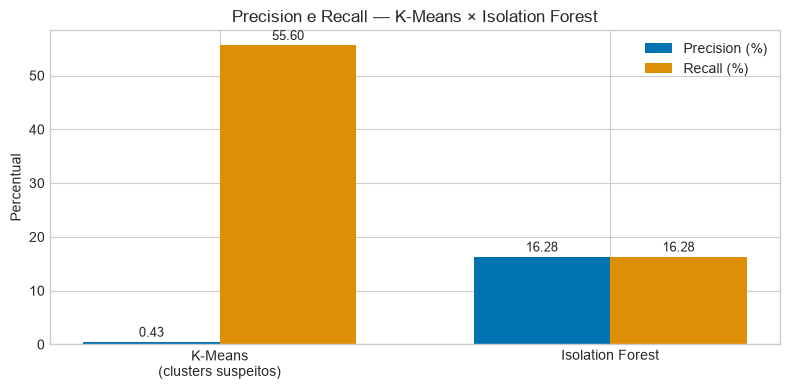

In [70]:
# Gráfico de barras comparando Precision e Recall
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(comparacao))
largura = 0.35

bars_p = ax.bar([i - largura/2 for i in x], comparacao["Precision (%)"], width=largura, label="Precision (%)")
bars_r = ax.bar([i + largura/2 for i in x], comparacao["Recall (%)"], width=largura, label="Recall (%)")

ax.set_xticks(list(x))
ax.set_xticklabels(["K-Means\n(clusters suspeitos)", "Isolation Forest"])
ax.set_ylabel("Percentual")
ax.set_title("Precision e Recall — K-Means × Isolation Forest")
ax.legend()

for bar in list(bars_p) + list(bars_r):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.5, f"{h:.2f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()


### Lendo o contraste

Os dois métodos respondem a **perguntas diferentes**:

1. **K-Means**  
   - Objetivo: descobrir **grupos** de comportamento.  
   - Uso prático: “estes segmentos merecem mais atenção humana”.  
   - Costuma marcar **muitas** transações como suspeitas (clusters inteiros) → Recall pode ser razoável, Precision costuma ser baixa.

2. **Isolation Forest**  
   - Objetivo: apontar **pontos atípicos**.  
   - Uso prático: lista mais enxuta de candidatos a investigação.  
   - Com `contamination` perto da taxa real, marca bem menos transações → o equilíbrio Precision/Recall muda.

**Nenhum dos dois é um detector perfeito isolado.**  
Em um sistema real, o caminho comum é **combinar**:

- segmentação (K-Means ou similar) para entender perfis  
- detector de anomalia (Isolation Forest, LOF, autoencoders…) para priorizar alertas  
- regras de negócio e revisão humana no final

> Lembrete de honestidade metodológica:  
> tanto a escolha dos clusters suspeitos quanto o valor de `contamination` usam informação agregada do próprio conjunto.  
> Para afirmar desempenho futuro, seria necessário validação em dados separados (treino / teste).


## 10. Conclusão

Além do K-Means, incluímos o **Isolation Forest** como contraste: um método feito para anomalias, não para agrupar.

1. É possível formar grupos de transações **sem usar** a informação de fraude.  
2. Alguns grupos apresentam taxa de fraude **várias vezes maior** que a média geral.  
3. Juntos, os grupos mais suspeitos concentraram uma parcela relevante das fraudes em uma fração menor das transações.  
4. Mesmo assim, a precisão do K-Means ficou baixa: a maior parte das transações nesses grupos continua legítima.  
5. O Isolation Forest, ao marcar bem menos transações, muda o equilíbrio entre Precision e Recall — e ilustra que **agrupar** e **detectar anomalia** são tarefas diferentes.

### Analogia final

Pense nos clusters como **filas de inspeção** em um aeroporto:

- Você descobriu que duas filas têm proporção maior de pessoas com risco.  
- Direcionar mais agentes para essas filas é inteligente.  
- Mas você **não** pode prender todo mundo que está nessas filas — a maioria é inocente.

### Transparencia

A escolha de quais clusters são “suspeitos” foi feita **depois** de olhar a taxa de fraude.  
Portanto, as métricas de Precision/Recall aqui são **retrospectivas** (no mesmo conjunto) e **não** devem ser lidas como desempenho esperado em transações futuras.  
Em um sistema real, seria necessário validar em dados que o modelo nunca viu.


## 11. Limitações (o que o projeto não resolve)

| Limitação | Por que importa |
|-----------|-----------------|
| Silhouette baixo | Os dados não formam grupos naturalmente bem separados; K-Means assume grupos mais compactos |
| Variáveis `V1`–`V28` anônimas | Impede interpretação rica de negócio dos perfis |
| Forte desbalanceamento | Qualquer filtro que aumente o Recall tende a gerar muitos falsos positivos |
| Escolha retrospectiva dos clusters suspeitos | Métricas de Precision/Recall não são estimativa de desempenho futuro |
| Influência de `Time` | Parte da separação pode ser temporal; vale testar com e sem essa variável |
| Um único algoritmo | K-Means não foi desenhado especificamente para anomalias |
| `contamination` informado com a taxa real | Útil didaticamente, mas em produção precisa de calibração em dados de validação |
| Comparação no mesmo conjunto | Métricas de ambos os métodos são retrospectivas |


## 12. Possíveis melhorias e próximos passos

### Curto prazo (ainda no mesmo espírito didático)

1. **Comparar k = 3, 5 e 8** lado a lado (tabela de taxas de fraude + tamanho).  
2. **Rodar com e sem a variável `Time`** e ver o quanto a segmentação muda.  
3. Criar um **“cartão de identidade”** de cada cluster (top 5 variáveis que mais se afastam da média).  

### Médio prazo (outros métodos não supervisionados)

- **Local Outlier Factor (LOF)** — densidade local (além do Isolation Forest já explorado)  
- **Local Outlier Factor (LOF)** — densidade local  
- **DBSCAN** — grupos de forma arbitrária + pontos de ruído  
- Redução de dimensionalidade (PCA/UMAP) **antes** da clusterização, só para visualização  

### Longo prazo (validação séria)

- Separar treino / validação / teste **antes** de qualquer análise  
- Definir a regra de “cluster suspeito” só no treino e medir Precision/Recall no teste  
- Comparar o ganho de priorização contra um baseline simples (ex.: maior `Amount`, horários noturnos etc.)

Essas extensões transformam o notebook de “demonstração didática” em um ponto de partida para um sistema de priorização mais robusto.


## Glossário rápido

| Termo | Significado em uma frase |
|-------|---------------------------|
| **Aprendizado supervisionado** | O algoritmo aprende com exemplos já rotulados (fraude / não fraude) |
| **Aprendizado não supervisionado** | O algoritmo busca padrões sem rótulos |
| **Cluster / grupo** | Conjunto de transações parecidas entre si |
| **K-Means** | Algoritmo que forma k grupos minimizando a distância ao centro de cada grupo |
| **Inércia** | Soma das distâncias dos pontos aos centros dos seus grupos (quanto menor, mais compacto) |
| **Silhouette Score** | Medida de quão bem separados e compactos estão os grupos (−1 a +1) |
| **Padronização** | Transformar variáveis para média 0 e desvio 1, para que a escala não domine |
| **PCA** | Técnica que comprime muitas variáveis em componentes principais (usado na origem deste dataset) |
| **Precision** | Das que marquei como suspeitas, quantas eram fraude de verdade? |
| **Recall** | Das fraudes existentes, quantas eu consegui marcar como suspeitas? |
| **F1-Score** | Média harmônica entre Precision e Recall |
| **Desbalanceamento** | Uma classe (fraude) é muito mais rara que a outra |
| **Anomalia / outlier** | Ponto que se desvia fortemente do padrão geral dos dados |
| **Isolation Forest** | Algoritmo que isola pontos atípicos com árvores aleatórias; anomalias isolam-se mais rápido |
| **Contamination** | Fração estimada de anomalias que o Isolation Forest deve procurar |


## Como citar / origem dos dados

- Conjunto de dados: [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) (Machine Learning Group — ULB)  
- Este notebook é uma reescrita didática focada em clareza e narrativa, mantendo a lógica de análise não supervisionada com K-Means.

---

**Fim do notebook.**  